In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif, mutual_info_classif
from ucimlrepo import fetch_ucirepo # Importação de Dados
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Carga de Dados

In [3]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

# União das Linhas e Colunas
df_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_iot2022.shape}')
print(f'Target: {target_column}\n')

df_iot2022.head(5)

Shape: (123117, 84)
Target: Attack_type



,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,761.985779,29729182.96,32011597.87,4001449.734,10403073.63,4438.877106,1511693.954,2.026391e+06,506597.757339,680406.147100,761.985779,29729182.96,32011597.87,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2282414.913,2282414.913,2282414.913,2282414.913,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,247.001648,29855277.06,31883584.02,3985448.003,10463455.56,4214.048386,1576435.804,1.876261e+06,469065.249000,741351.686200,247.001648,29855277.06,31883584.02,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2028306.961,2028306.961,2028306.961,2028306.961,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,283.956528,29842149.02,32124053.00,4015506.625,10442377.92,2456.903458,1476048.946,2.013770e+06,503442.466300,660344.360027,283.956528,29842149.02,32124053.00,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2281903.982,2281903.982,2281903.982,2281903.982,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,288.963318,29913774.97,31961063.15,3995132.893,10482528.22,3933.906555,1551892.042,1.883784e+06,470946.013927,724569.317900,288.963318,29913774.97,31961063.15,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2047288.179,2047288.179,2047288.179,2047288.179,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,387.907028,29814704.90,31902361.87,3987795.234,10447019.10,3005.027771,1632083.178,1.935984e+06,483996.033700,768543.390313,387.907028,2981

# 2) Análise de Dados

### 2.1) Report Básico

In [4]:
df = df_iot2022.copy()
numeric_columns = df.select_dtypes(include=np.number).columns.to_list()

Avaliação de Valores Contantes

In [5]:
constant_columns = [c for c in df.columns if df[c].nunique() <= 1]

# Ao apresentar pelo menos uma coluna constante, o ideal seria remove-las para evitar ruídos
for c in constant_columns:
    print(f'{c}: {pd.unique(df[c])}')

bwd_URG_flag_count: [0]


Avaliação Básica

In [10]:
# Avaliação de Calores numéricos
report = {}

# Quantidade de Valores Nulos
report['nulos'] = int(df.isnull().sum().sum())
report['%_nulos'] = round(int(df.isnull().sum().sum())/len(df) * 100, 2)

# Quantidade de Colunas numéricas
report['colunas_numericas'] = len(numeric_columns)

# Valores Infinitos
report['valores_infinitos'] = np.isinf(df[numeric_columns]).sum().sum()

# Valores Negativos
report['negativos'] = int((df[numeric_columns] < 0).sum().sum())

# Avaliação de Duplicadas
report['duplicadas_antes'] = len(df)
df = df.drop_duplicates().reset_index(drop=True)
report['duplicadas_removidas'] = report['duplicadas_antes'] - len(df)

# Remoção das colunas constantes
df = df.drop(columns=constant_columns)

report['constantes_removidas'] = constant_columns

# Shape Principal
report['shape_principal'] = df.shape

# Atualização das Colunas Numéricas:
numeric_columns = df.select_dtypes(include=np.number).columns.to_list()

print(pd.Series(report))

nulos                                      0
%_nulos                                  0.0
colunas_numericas                         81
valores_infinitos                          0
negativos                                  0
duplicadas_antes                      123117
duplicadas_removidas                    5195
constantes_removidas    [bwd_URG_flag_count]
shape_principal                 (117922, 83)
dtype: object


Colunas com rótulos diferentes

In [12]:
features = [c for c in df.columns if c != target_column]
conflitos = df.groupby(features)[target_column].nunique()

print(f'{(conflitos > 1).sum()} grupos com rótulos diferentes')

6 grupos com rótulos diferentes


Análise Descritiva

In [ ]:
print(df[numeric_columns].describe().head(20))

           id.orig_p      id.resp_p  flow_duration   fwd_pkts_tot  \
count  117922.000000  117922.000000  117922.000000  117922.000000   
mean    34949.094317    1050.812266       3.808474       2.290209   
std     18966.047699    5364.536754     127.064242      22.111453   
min         0.000000       0.000000       0.000000       0.000000   
25%     18352.250000      21.000000       0.000001       1.000000   
50%     37534.000000      21.000000       0.000004       1.000000   
75%     51036.000000      21.000000       0.000005       1.000000   
max     65535.000000   65389.000000   21728.335580    4345.000000   

        bwd_pkts_tot  fwd_data_pkts_tot  bwd_data_pkts_tot  fwd_pkts_per_sec  \
count  117922.000000      117922.000000      117922.000000      1.179220e+05   
mean        1.942776           1.470506           0.847594      3.510607e+05   
std        33.727670          19.286029          32.989078      3.707032e+05   
min         0.000000           0.000000           0.000000

In [13]:
df[target_column].value_counts()

Attack_type
DOS_SYN_Hping                 90089
Thing_Speak                    7654
ARP_poisioning                 7625
MQTT_Publish                   4142
NMAP_UDP_SCAN                  2584
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  533
Wipro_bulb                      219
Metasploit_Brute_Force_SSH       36
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

### 2.2) Distribuição do Target

In [ ]:
def plot_volumetry(df: pd.DataFrame, target: str):
    """ 
    Avaliar o quanto a coluna 'target' está bem distribuída conforme suas classes
    """
    # Contagem por Classe
    df_volumetry = df[target].value_counts()
    df_percent = round(df[target].value_counts(normalize=True) * 100, 2)

    _, axes = plt.subplots(1, 2, figsize=(15,5))

    axes[0].bar(df_volumetry.index.astype(str), df_volumetry.values, color='steelblue')
    axes[0].set_title(f'Contagem por classe — {target}')
    axes[0].set_ylabel('Contagem')

    for i, v in enumerate(df_volumetry.values):
        axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
    axes[0].tick_params(axis='x', rotation=90)


    axes[1].bar(df_percent.index.astype(str), df_percent.values, color='darkorange')
    axes[1].set_title('Proporção das classes (%)')
    axes[1].set_ylabel('Percentual (%)')

    for i, v in enumerate(df_percent.values):
        axes[1].text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=8)
    axes[1].tick_params(axis='x', rotation=90)
    
    plt.show()

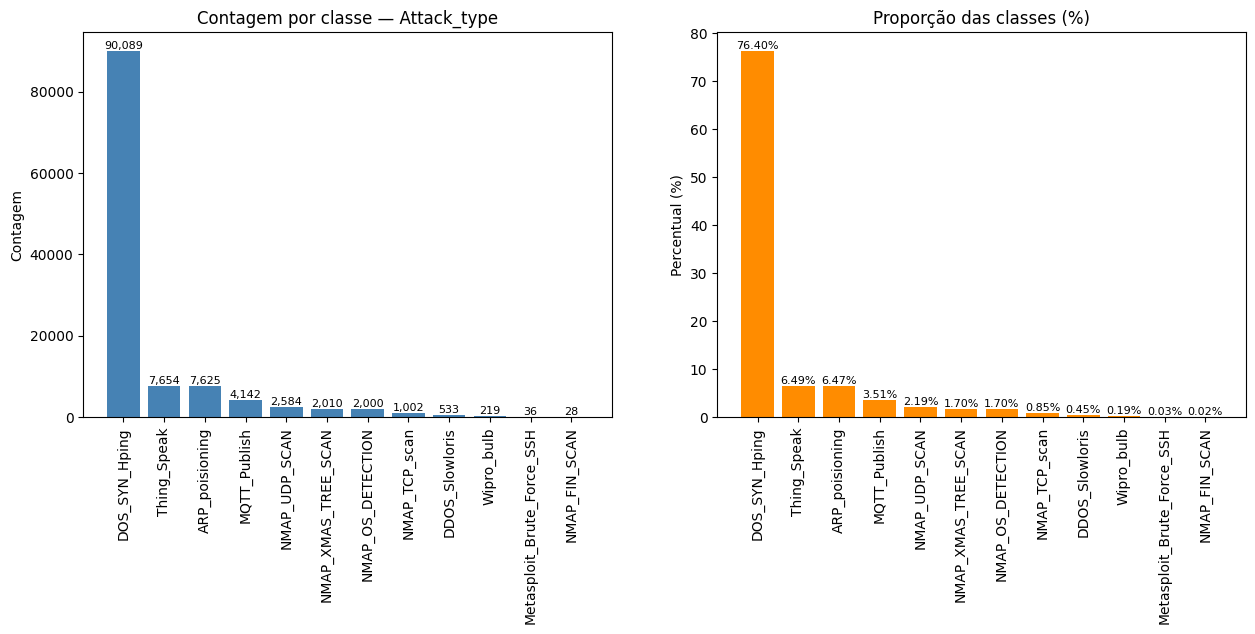

In [ ]:
plot_volumetry(df=df, target=target_column)

### 2.3) Identificação de Outliers

In [ ]:
def outlier_detection(pd_series: pd.Series):
    """ 
    Detecção de Outliers através da diferença entre o terceiro e o primeiro qquartil 
    """
    Q1 = pd_series.quantile(0.25)
    Q3 = pd_series.quantile(0.75)
    IQR = Q3 - Q1 

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR) 

    return int(((pd_series < lower_limit) | (pd_series > upper_limit)).sum())

Quantidade de Colunas com mais outliers: 75


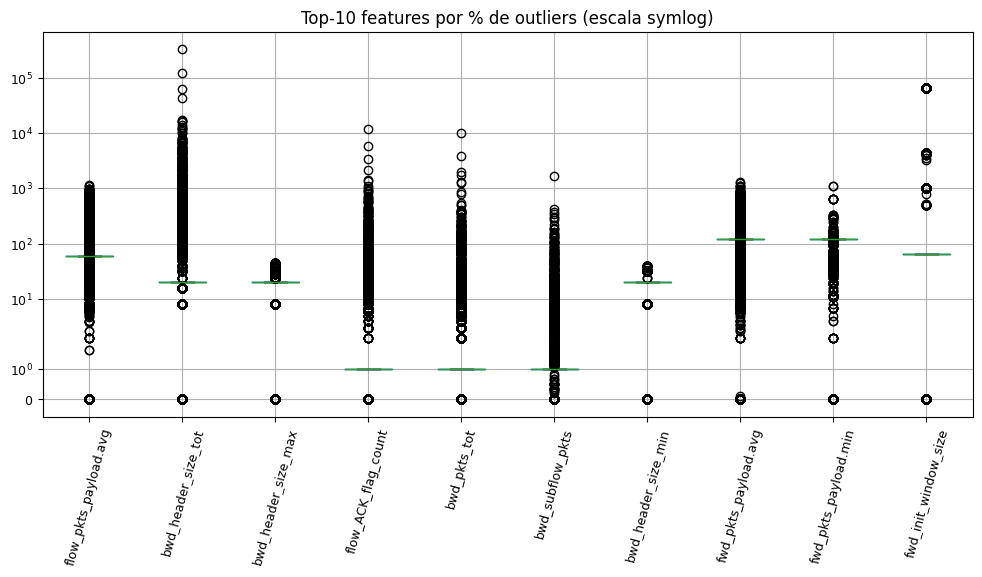

In [ ]:
df_outliers = df[numeric_columns].apply(outlier_detection).sort_values(ascending=False).reset_index(name="qtd_outliers").rename(columns={"index": "feature"})
df_outliers['pct_outliers'] = round(df_outliers['qtd_outliers']/len(df) * 100, 2)

print(f"Quantidade de Colunas com mais outliers: {len(df_outliers[df_outliers['qtd_outliers'] > 0])}")

top_10_outliers = df_outliers.sort_values(by='qtd_outliers', ascending=False).head(10)['feature']

fig, ax = plt.subplots(figsize=(12, 5))
df[top_10_outliers].boxplot(ax=ax, rot=75, fontsize=9)
ax.set_title('Top-10 features por % de outliers')
ax.set_yscale('symlog')
ax.set_title('Top-10 features por % de outliers (escala symlog)')

plt.show()

# 3) Relevância das Features

### 3.1) Correlação entre Variáveis Categoricas

In [ ]:
def cramers_v(var1, var2):
    """
    Lógica de Implementção do V-Cramers para validar a correlação 
    entre as colunas categóricas com a coluna target
    """
    main_table = pd.crosstab(var1, var2)

    chi2 = chi2_contingency(main_table)[0]

    n = main_table.sum().sum()
    r, k = main_table.shape

    # Logica do V Cramer
    phi2 = chi2 / n
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)

    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    min_corr = min(k_corr - 1, r_corr - 1)

    return np.sqrt(phi2corr/min_corr) if min_corr != 0 else 0

In [ ]:
categorical_columns = [c for c in df.columns if c not in numeric_columns and c != target_column]

df_cramers = pd.DataFrame({
        "feature": categorical_columns,
        "cramers_v": [cramers_v(df[c], df[target_column]) for c in categorical_columns]
    }
).sort_values(by='cramers_v', ascending=False)

print(df_cramers)

print(f'\nQuantidade de Valores únicos por coluna categórica')
print({c: df[c].nunique()  for c in categorical_columns})

   feature  cramers_v
1  service   0.589579
0    proto   0.584545

Quantidade de Valores únicos por coluna categórica
{'proto': 3, 'service': 10}


### 3.2) Avaliação das Relações Lineares

In [ ]:
df_encoded = pd.get_dummies(data=df, columns=categorical_columns, drop_first=True, dtype=int)

X_numeric = df_encoded.drop(columns=target_column)
y_encoded = LabelEncoder().fit_transform(df['Attack_type'])

print(f'Features para as Relações Lineares: {X_numeric.shape[1]}')

Features para as Relações Lineares: 91


In [ ]:
# Detecta as relações lineares entre as colunas numéricas e a variável target
f_scores, p_value = f_classif(X=X_numeric, y=y_encoded)

# Detecta as relações lineares e não lineares entre as colunas numéricas e a variável target
mi_scores = mutual_info_classif(X_numeric, y_encoded, discrete_features=False, random_state=42)

df_scores = pd.DataFrame(
    {
        "feature": X_numeric.columns, 
        "f1_anova": f_scores,
        "p_value": p_value,
        "mi":  mi_scores
    }
)

df_scores = df_scores.merge(df_cramers, on='feature', how='left')
df_scores = df_scores.sort_values('mi', ascending=False).reset_index(drop=True)

df_scores.head(20)

,feature,f1_score,p_value,mi,cramers_v
0,fwd_pkts_payload.avg,22305.890873,0.000000e+00,0.877798,NaN
1,fwd_pkts_payload.max,1963.127511,0.000000e+00,0.874025,NaN
2,fwd_subflow_bytes,455.711658,0.000000e+00,0.867967,NaN
3,flow_pkts_payload.tot,16.522088,4.768145e-33,0.865079,NaN
4,fwd_pkts_payload.tot,143.262220,0.000000e+00,0.862311,NaN
5,flow_pkts_payload.avg,2967.146094,0.000000e+00,0.859967,NaN
6,flow_pkts_payload.max,3403.678585,0.000000e+00,0.858679,NaN
7,id.resp_p,7937.346600,0.000000e+00,0.812056,NaN
8,fwd_last_window_size,82702.053970,0.000000e+00,0.780318,NaN
9,flow_pkts_payload.std,2013.441367,0.000000e+00,0.711875,NaN


### 3.3) Investigação das Features

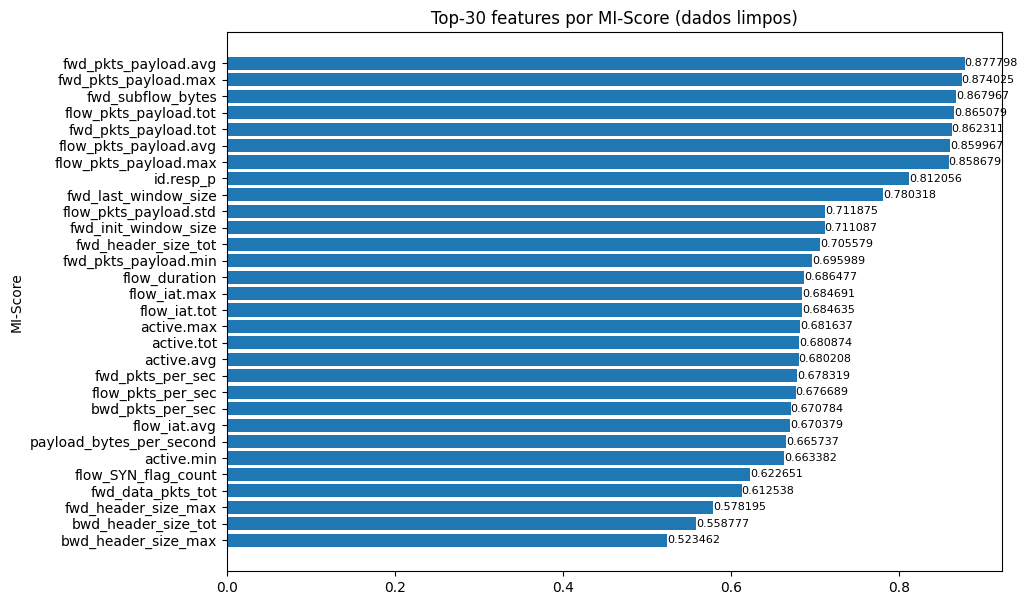

In [ ]:
top_30_mi = df_scores.head(30).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_30_mi['feature'], top_30_mi['mi'])
ax.set_title("Top-30 features por MI-Score (dados limpos)")
ax.set_ylabel("MI-Score")

for container in ax.containers:
    ax.bar_label(container, fontsize=8)

plt.show()

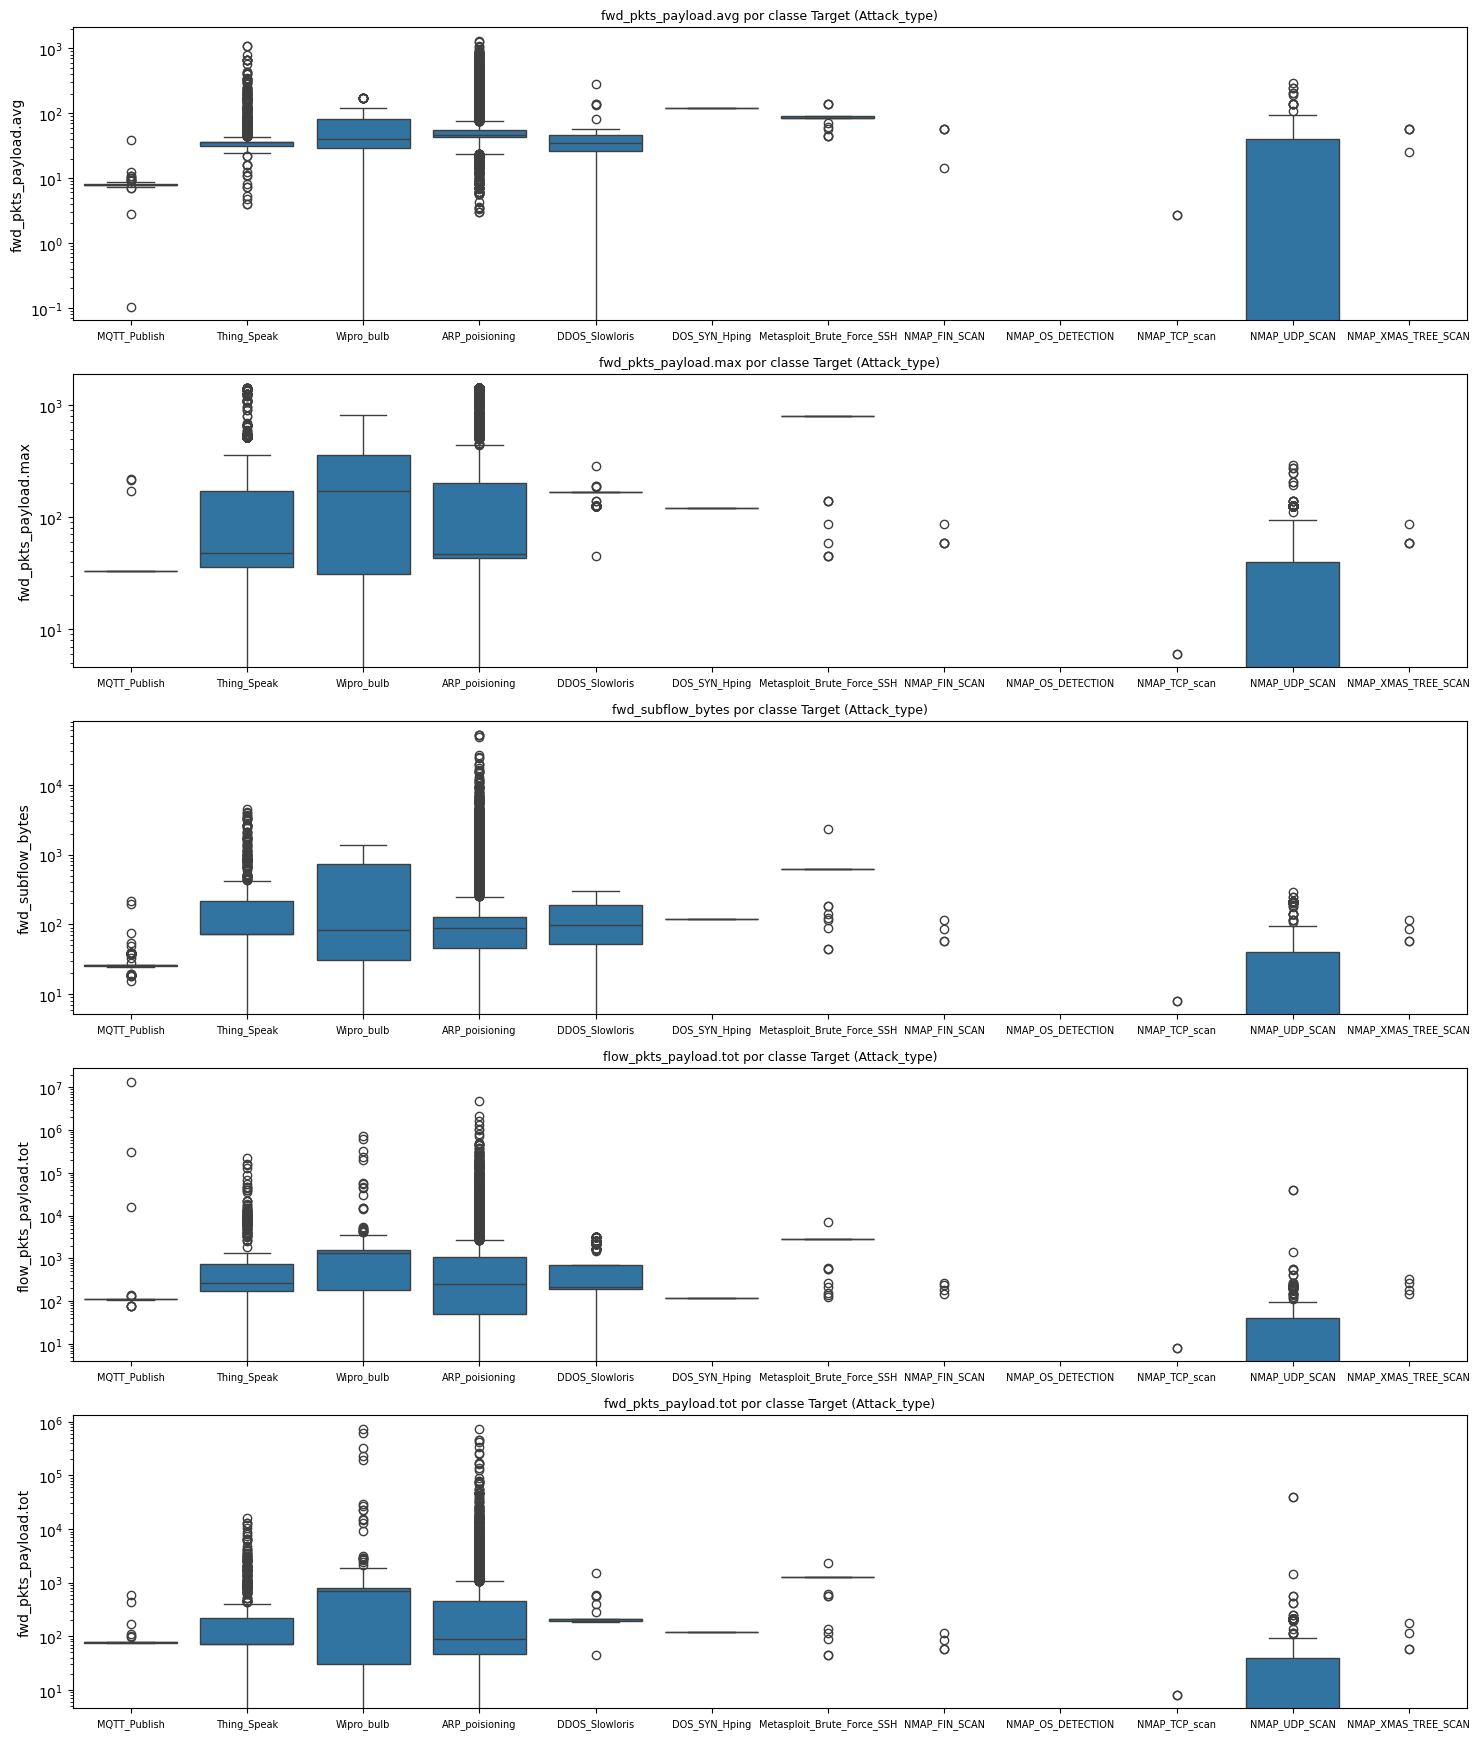

In [ ]:
# Boxplot da classe de top 5 colunas colunas
df_top5 = df_scores.head(5)['feature'].to_list()
df_top5 = [c for c in df_top5 if c in df.columns]

fig, axes = plt.subplots(len(df_top5), 1, figsize=(15, 3.5 * len(df_top5)))

for ax, feature in zip(axes, df_top5):
    sns.boxplot(data=df, x=target_column, y=feature, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'{feature} por classe Target ({target_column})', fontsize=9)
    ax.tick_params(axis='x', labelsize=7)
    ax.set_xlabel("")

fig.subplots_adjust(hspace=1)
plt.tight_layout()
plt.show()

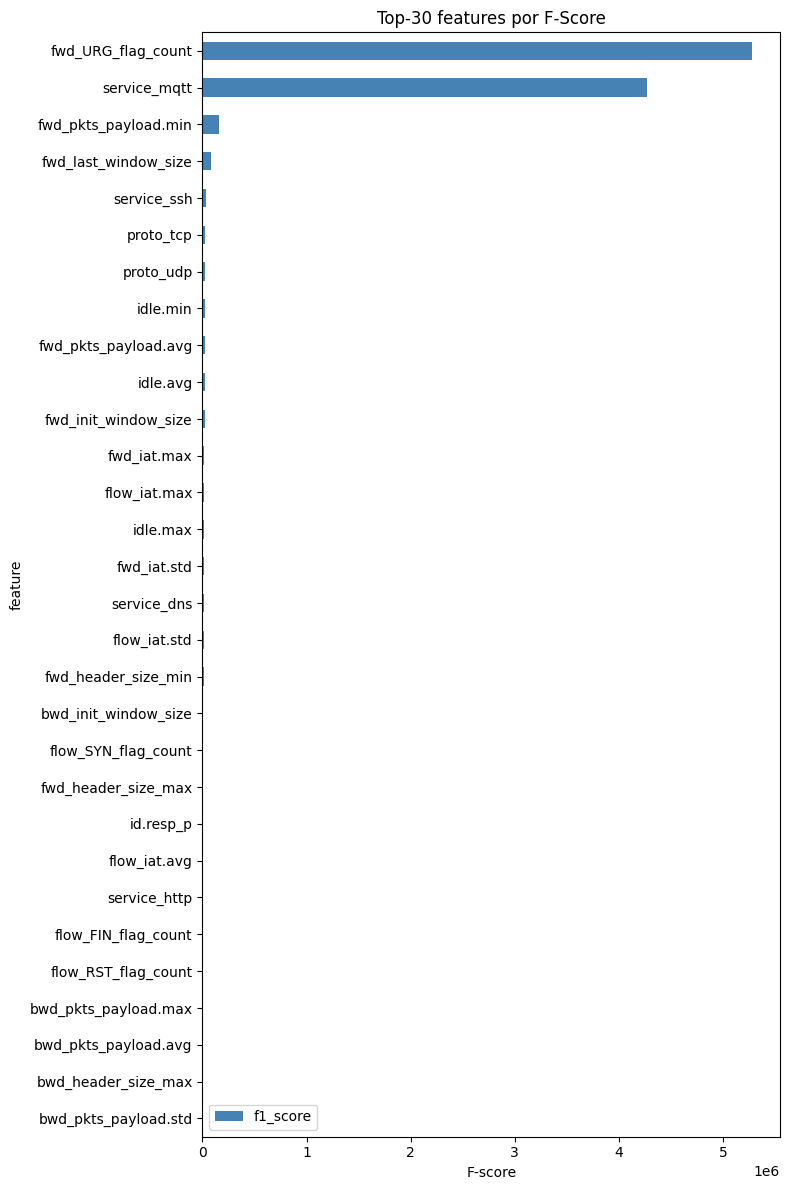

In [ ]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.sort_values(by='f1_anova', ascending=False).head(30).iloc[::-1].plot.barh(
    x='feature', y='f1_anova', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por F1-Anova')
ax.set_xlabel('F-score')
plt.tight_layout()
plt.show()


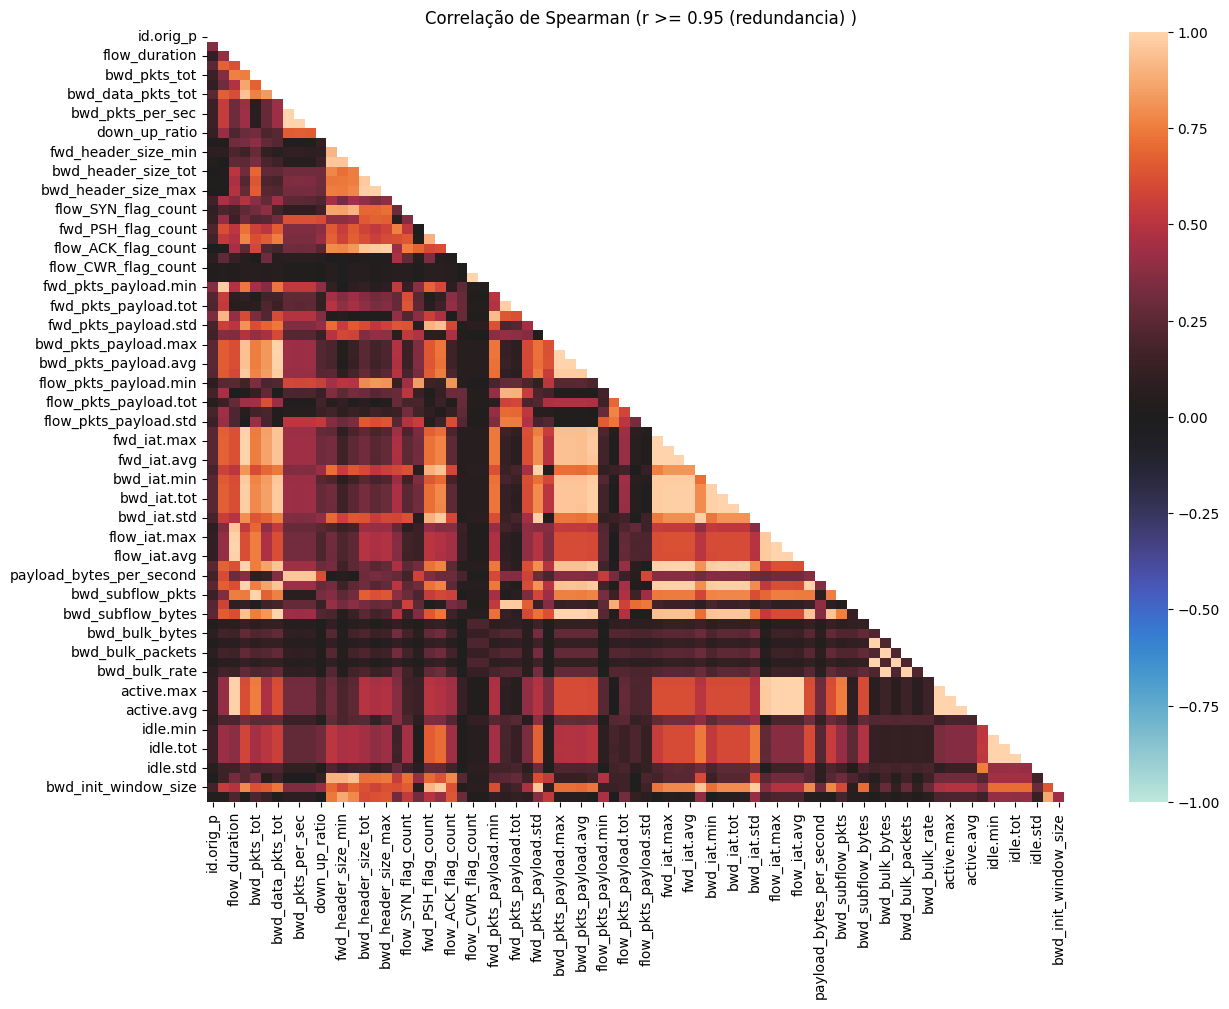

In [ ]:
# Heatmap
df_numeric_correlations = df[numeric_columns].corr(method='spearman').abs()
masked = np.triu(np.ones_like(df_numeric_correlations))

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(
    data=df_numeric_correlations, 
    mask=masked, center=0, vmin=-1, vmax=1
)

plt.title("Correlação de Spearman (r >= 0.95 (redundancia) )")
plt.show()

Ao verificar a alta correlação será agrupado as colunas mais correlacionadas, e então removê-las pelo MI-Score

In [ ]:
def correlated_agroupment(corr_list, threshold=0.95):
    """ 
    Retorna uma lista de grupos que estão correlacionadas em cadeia
    """
    groups, correlation_set = [], set(corr_list)

    while correlation_set:
        column = correlation_set.pop()
        group = {column}
        changed = True 
        while changed:
            changed = False 
            for col in list(correlation_set):
                if any(corr_list.loc[col, membro] > threshold for membro in group):
                    group.add(col)
                    correlation_set.remove(col)
                    changed = True

        groups.append(group)

    return groups


def choose_columns(group_list: list[dict], importances:dict):
    """ 
    Para cada grupo será escolhido a feature com mais importância
    """
    keep_columns = []
    remove_columns = []

    for g in group_list:
        if len(g) == 1:
            keep_columns.append(next(iter(g)))
            continue
        
        best = max(g, key=lambda f: importances.get(f))
        keep_columns.append(best)
        remove_columns.extend(g - {best})

    return keep_columns, remove_columns


In [ ]:
upper = df_numeric_correlations.where(np.triu(np.ones(df_numeric_correlations.shape), k=1).astype(bool))
print(f'Total de Colunas Redundantes: {len([c for c in upper.columns if (upper[c] > 0.95).any()])}\n')

groups = correlated_agroupment(corr_list=upper)
importances = dict(zip(df_scores['feature'], df_scores['mi']))

print(f'Quantidade de grupos correlacionados: {len(groups)}')

keep_columns, remove_columns = choose_columns(group_list=groups, importances=importances)

print(f'Manter as colunas: {keep_columns}')
print(f'Remover as colunas: {remove_columns}')
print(f'Total para ser Removido: {len(remove_columns)}')

Total de Colunas Redundantes: 46

Quantidade de grupos correlacionados: 43
Manter as colunas: ['fwd_init_window_size', 'idle.std', 'bwd_bulk_bytes', 'fwd_pkts_payload.max', 'flow_duration', 'fwd_pkts_tot', 'bwd_header_size_tot', 'fwd_bulk_bytes', 'active.std', 'active.max', 'idle.min', 'bwd_pkts_payload.tot', 'bwd_bulk_rate', 'bwd_pkts_tot', 'fwd_pkts_payload.std', 'fwd_pkts_per_sec', 'id.resp_p', 'flow_pkts_payload.tot', 'flow_CWR_flag_count', 'fwd_URG_flag_count', 'bwd_subflow_bytes', 'flow_RST_flag_count', 'flow_pkts_payload.avg', 'fwd_header_size_min', 'flow_pkts_payload.min', 'fwd_PSH_flag_count', 'fwd_header_size_tot', 'bwd_header_size_max', 'flow_ECE_flag_count', 'down_up_ratio', 'fwd_pkts_payload.avg', 'flow_pkts_payload.std', 'flow_pkts_per_sec', 'fwd_last_window_size', 'fwd_data_pkts_tot', 'idle.avg', 'bwd_pkts_payload.min', 'flow_iat.std', 'bwd_subflow_pkts', 'id.orig_p', 'flow_SYN_flag_count', 'flow_FIN_flag_count', 'flow_pkts_payload.max']
Remover as colunas: ['bwd_bulk_pa

# 4) Conclusões

### Sobre os Dados
- (123.117 linhas x 84 colunas) (81 numéricas, 3 categóricas)

- Não apresenta valores nulos (Não precisa adaptar)

- Não apresenta valores negativos

- Apresenta 5195 valores duplicados (4.22% do total) -> deve remover antes do split

- o Outlier é apresentado em até 31% em algumas colunas (sendo elas 'flow_pkts_payload.avg' e 'bwd_header_size_tot')


### Sobre A coluna target (Attack_Type)

- São divididas em 12 categorias com grave desbalanceamento
  * DOS_SYN_Hping (aproximandamente 76%)
  * Enquanto as outras classes vao de 6.5% para baixo
- **Conclusão**: a acurácia é enganosa (ocorre quando um modelo assume que a classe majoritária acerta)


### Sobre As correlações

- Apresentaram colunas que geram uma alta redundância em si, tornando o modelo ineficaz, Portanto ao reavaliar as colunas por meio das medidas de correlção e então agrupá-las para verificar qual é a melhor através do MI-Score, poderão ser removidas 37 colunas


